In [ ]:
!pip install protobuf==5.29.5
!pip install tensorflow==2.19.0
!pip install mediapipe==0.10.21
#!pip install mediapipe==0.10.14

  Using cached protobuf-5.29.5-cp38-abi3-manylinux2014_x86_64.whl.metadata (592 bytes)
Using cached protobuf-5.29.5-cp38-abi3-manylinux2014_x86_64.whl (319 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 4.25.9
    Uninstalling protobuf-4.25.9:
      Successfully uninstalled protobuf-4.25.9
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mediapipe 0.10.21 requires protobuf<5,>=4.25.3, but you have protobuf 5.29.5 which is incompatible.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.19.0 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.19.0 which is incompatible.
tf-keras 2.20.0 requires tensorflow<2.21,>=2.20, but you have tensorflow 2.19.0 which is incompatible.


  Using cached protobuf-4.25.9-cp37-abi3-manylinux2014_x86_64.whl.metadata (541 bytes)
Using cached protobuf-4.25.9-cp37-abi3-manylinux2014_x86_64.whl (295 kB)
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled protobuf-5.29.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.19.0 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.19.0 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.
grain 0.2.18 requires protobuf>=5.28.3, but you have protobuf 4.25.9 which is incompatible.
tf-keras 2.20.0 requires tensorflow<2.21,>=2.20, but you have tensorflow 2.19.0 which is inco

In [ ]:
!pip freeze > /content/drive/MyDrive/requirements.txt

In [ ]:
from tqdm import tqdm
import time

pbar = tqdm(range(10))
for i in pbar:
    pbar.set_postfix({"current_value": i, "status": "running"})
    time.sleep(0.1)

100%|██████████| 10/10 [00:01<00:00,  9.78it/s, current_value=9, status=running]


In [ ]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

from google.colab.patches import cv2_imshow
from IPython.display import clear_output
import time

import csv
from datetime import datetime
import re
import math

Mounted at /content/drive


In [ ]:
#####CSV



fecha = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
nombre_archivo = f"/content/drive/MyDrive/results/archivo_{fecha}.csv"

print(nombre_archivo)

headers = [[
    "nose",
    "left_eye_inner",
    "left_eye",
    "left_eye_outer",
    "right_eye_inner",
    "right_eye",
    "right_eye_outer",
    "left_ear",
    "right_ear",
    "mouth_left",
    "mouth_right",
    "left_shoulder",
    "right_shoulder",
    "left_elbow",
    "right_elbow",
    "left_wrist",
    "right_wrist",
    "left_pinky",
    "right_pinky",
    "left_index",
    "right_index",
    "left_thumb",
    "right_thumb",
    "left_hip",
    "right_hip",
    "left_knee",
    "right_knee",
    "left_ankle",
    "right_ankle",
    "left_heel",
    "right_heel",
    "left_foot_index",
    "right_foot_index",
    "coordinate",
    "Frame"
]]


with open(nombre_archivo, mode="w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerows(headers)

print("CSV creado correctamente")

/content/drive/MyDrive/results/archivo_2026-06-08_23-14-32.csv
CSV creado correctamente


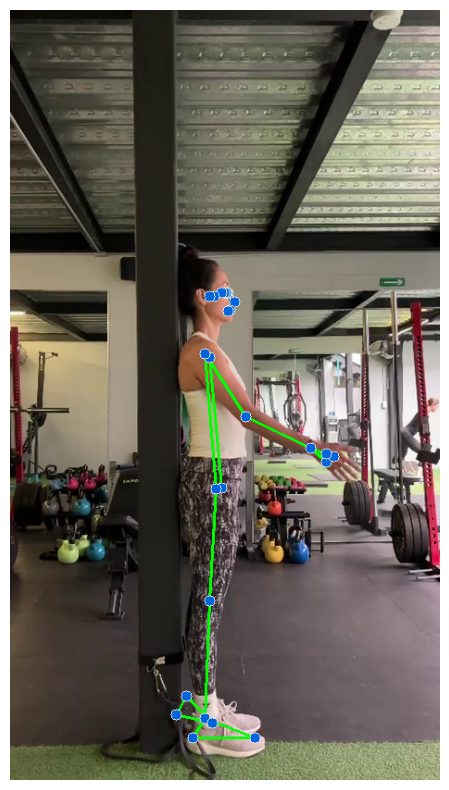

KeyboardInterrupt: 

In [ ]:

cap = cv2.VideoCapture('/content/drive/MyDrive/mov.mp4')

mp_pose = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils

frame_counter = 0

with mp_pose.Pose(static_image_mode=False) as pose:

    while True:

        ret, img = cap.read()

        if not ret:
            break

        img_height, img_width, _ = img.shape

        # Procesar frame
        results = pose.process(img)

        annotated_img = img.copy()

        if results.pose_landmarks:

            # Tamaño dinámico de puntos
            circle_radius = int(0.007 * img_height)

            point_spec = mp_drawing.DrawingSpec(
                color=(220,100,0),
                thickness=-1,
                circle_radius=circle_radius
            )

            line_spec = mp_drawing.DrawingSpec(
                color=(0,255,0),
                thickness=2
            )

            mp_drawing.draw_landmarks(
                annotated_img,
                landmark_list=results.pose_landmarks,
                connections=mp_pose.POSE_CONNECTIONS,
                landmark_drawing_spec=point_spec,
                connection_drawing_spec=line_spec
            )

        clear_output(wait=True)

        plt.figure(figsize=(10,10))
        plt.imshow(annotated_img[...,::-1])
        plt.axis("off")
        plt.show()

        time.sleep(1)

        frame_counter += 1
'''
    if results.pose_landmarks is not None:
      x_vals = [landmark.x for landmark in results.pose_landmarks.landmark]
      y_vals = [landmark.y for landmark in results.pose_landmarks.landmark]
      #print("X:", x_vals)
      #print("Y:", y_vals)
      x_vals.append("X")
      y_vals.append("Y")
      x_vals.append(frame_counter)
      y_vals.append(frame_counter)

      data = [x_vals,y_vals]
      with open(nombre_archivo, mode="a", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerows(data)
'''
cap.release()





In [ ]:
class Point:
    def __init__(self, x, y):
        self.x = x
        self.y = y

class Body:
    def __init__(self):
        self.frame = 0
        self.points = []   # arreglo dinámico vacío

    def AddPoint(self, point):
        self.points.append(point)

    def SetFrame(self, frame):
        self.frame = frame

    def ToArray(self):
        return [(point.x, point.y) for point in self.points]

    def GetAngle(self, point1, vertex, point3):

        if max(point1, vertex, point3) >= len(self.points):
            raise ValueError("Índice fuera de rango")

        p1 = self.points[point1]
        p2 = self.points[vertex]
        p3 = self.points[point3]

        # Vectores desde el vértice
        v1 = (p1.x - p2.x, p1.y - p2.y)
        v2 = (p3.x - p2.x, p3.y - p2.y)

        # Producto punto
        dot = v1[0] * v2[0] + v1[1] * v2[1]

        # Magnitudes
        mag1 = math.sqrt(v1[0]**2 + v1[1]**2)
        mag2 = math.sqrt(v2[0]**2 + v2[1]**2)

        if mag1 == 0 or mag2 == 0:
            raise ValueError(
                "No se puede calcular el ángulo con un vector de longitud cero"
            )

        cos_angle = dot / (mag1 * mag2)

        # Evitar errores numéricos
        cos_angle = max(-1, min(1, cos_angle))

        angle = math.degrees(
            math.acos(cos_angle)
        )

        return angle

def LoadBodies(file):
    bodies = []

    with open(file, mode='r', newline='', encoding='utf-8') as file:
        reader = csv.DictReader(file)
        rows = list(reader)

        # Procesamos de dos en dos: X y Y
        for i in range(0, len(rows), 2):
            row_x = rows[i]
            row_y = rows[i + 1]

            body = Body()
            body.SetFrame(int(row_x["Frame"]))

            # Excluir columnas auxiliares
            excluded = ["coordinate", "Frame"]

            for key in row_x:
                if key not in excluded:
                    x = float(row_x[key])
                    y = float(row_y[key])

                    point = Point(x, y)
                    body.AddPoint(point)

            bodies.append(body)

    return bodies




In [ ]:
class VideoProcessor:
    def __init__(self, video_path, bodies):
        self.video = cv2.VideoCapture(video_path)
        self.bodies = bodies

        if not self.video.isOpened():
            raise ValueError(
                f"No se pudo abrir el video: {video_path}"
            )

    def ShowFrame(self, frame_number):

        if frame_number <= 0:
            raise ValueError(
                "frame_number debe ser mayor que cero"
            )

        # Buscar body correspondiente
        body = None

        for b in self.bodies:
            if b.frame == frame_number:
                body = b
                break

        if body is None:
            raise ValueError(
                f"No existe un Body para el frame {frame_number}"
            )

        # Posicionar video
        self.video.set(
            cv2.CAP_PROP_POS_FRAMES,
            frame_number - 1
        )

        success, frame = self.video.read()

        if not success:
            raise ValueError(
                f"No se pudo leer el frame {frame_number}"
            )

        # Convertir BGR → RGB
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        height, width, _ = frame.shape

        # Convertir una sola vez coordenadas normalizadas → píxeles
        coords = [
            (
                int(p.x * width),
                int(p.y * height)
            )
            for p in body.points
        ]

        # Dibujar puntos
        for x, y in coords:
            cv2.circle(
                frame,
                (x, y),
                5,
                (255, 0, 0),
                -1
            )

        # Conexiones MediaPipe
        skeleton = [
            (15, 21), (16, 20), (18, 20), (3, 7),
            (14, 16), (23, 25), (28, 30), (11, 23),
            (27, 31), (6, 8), (15, 17), (24, 26),
            (16, 22), (4, 5), (5, 6), (29, 31),
            (12, 24), (23, 24), (0, 1), (9, 10),
            (1, 2), (0, 4), (11, 13), (30, 32),
            (28, 32), (15, 19), (16, 18), (25, 27),
            (26, 28), (12, 14), (17, 19), (2, 3),
            (11, 12), (27, 29), (13, 15)
        ]

        # Dibujar esqueleto
        for start, end in skeleton:

            if start < len(coords) and end < len(coords):

                cv2.line(
                    frame,
                    coords[start],
                    coords[end],
                    (0, 255, 0),
                    2
                )

        plt.figure(figsize=(10, 8))
        plt.imshow(frame)
        plt.axis("off")
        plt.show()

In [ ]:
Bodies = LoadBodies(f"/content/drive/MyDrive/results/archivo_2026-04-17_17-05-52.csv")

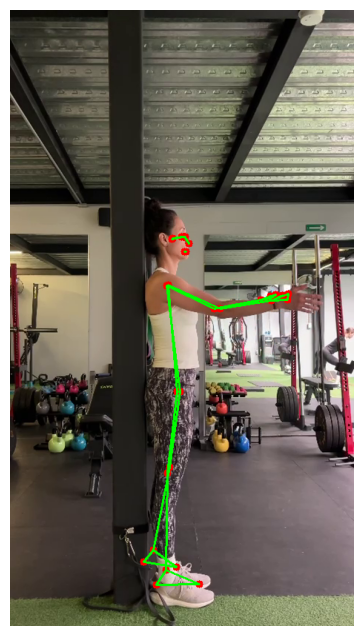

Angulo de hombro derecho: 67.32209362763547


KeyboardInterrupt: 

In [ ]:
processor = VideoProcessor(
    "/content/drive/MyDrive/mov.mp4",
    Bodies
)

for frame in range(1, len(Bodies) + 1):

    clear_output(wait=True)

    processor.ShowFrame(frame)
    print("Angulo de hombro derecho: " + str(Bodies[frame - 1].GetAngle(14,12,24)))

    time.sleep(1)  # ~30 FPS

In [ ]:
from openpyxl import Workbook


def ExportShoulderAngles(bodies, output_file):
    """
    Exporta a un archivo Excel los ángulos del hombro derecho
    para cada Body.

    Parámetros:
        bodies: lista de objetos Body.
        output_file: nombre del archivo .xlsx a generar.
    """

    workbook = Workbook()
    sheet = workbook.active
    sheet.title = "Shoulder Angles"

    # Encabezados
    sheet.append(["Frame", "Shoulder Angle"])

    # Datos
    for body in bodies:
        angle = body.GetAngle(14, 12, 24)
        sheet.append([body.frame, angle])

    workbook.save("/content/drive/MyDrive/results/" + output_file)

    print(f"Archivo guardado en: {output_file}")

In [ ]:
ExportShoulderAngles(
    Bodies,
    "ShoulderAngles.xlsx"
)

Archivo guardado en: ShoulderAngles.xlsx


In [ ]:

cap = cv2.VideoCapture('/content/drive/MyDrive/mov.mp4')

# Initializing the Pose and Drawing modules of MediaPipe.
mp_pose = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils
frame_counter = 0

while (True):
  ret, img = cap.read()
  if not ret:
    break
  # Getting the image's width and height.
  img_width = img.shape[1]
  img_height = img.shape[0]
  # Creating a figure and a set of axes.
  fig, ax = plt.subplots(figsize=(10, 10))
  ax.axis('off')
  ax.imshow(img[...,::-1])
  #plt.show()

  with mp_pose.Pose(static_image_mode=True) as pose:
    """
    This function utilizes the MediaPipe library to detect and draw 'landmarks'
    (reference points) on an image. 'Landmarks' are points of interest
    that represent various body parts detected in the image.

    Args:
        static_image_mode: a boolean to inform if the image is static (True) or sequential (False).
    """

    # Make a copy of the original image.
    annotated_img = img.copy()

    # Processes the image.
    results = pose.process(img)

    # Set the circle radius for drawing the 'landmarks'.
    # The radius is scaled as a percentage of the image's height.
    circle_radius = int(.007 * img_height)

    # Specifies the drawing style for the 'landmarks'.
    point_spec = mp_drawing.DrawingSpec(color=(220, 100, 0), thickness=-1, circle_radius=circle_radius)

    # Draws the 'landmarks' on the image.
    mp_drawing.draw_landmarks(annotated_img,
                              landmark_list=results.pose_landmarks,
                              landmark_drawing_spec=point_spec)


  annotated_img = img.copy()

  # Specifies the drawing style for landmark connections.
  line_spec = mp_drawing.DrawingSpec(color=(0, 255, 0), thickness=2)

  # Draws both the landmark points and connections.
  mp_drawing.draw_landmarks(
  annotated_img,
  landmark_list=results.pose_landmarks,
  connections=mp_pose.POSE_CONNECTIONS,
  landmark_drawing_spec=point_spec,
  connection_drawing_spec=line_spec
  )

  clear_output(wait=True)
  plt.imshow(annotated_img[...,::-1])
  plt.show()
  time.sleep(.5)

  # Fill CSV with landmarks
  frame_counter+=1

  if results.pose_landmarks is not None:
    x_vals = [landmark.x for landmark in results.pose_landmarks.landmark]
    y_vals = [landmark.y for landmark in results.pose_landmarks.landmark]
    print("X:", x_vals)
    print("Y:", y_vals)
    x_vals.append("X")
    y_vals.append("Y")
    x_vals.append(frame_counter)
    y_vals.append(frame_counter)

    data = [x_vals,y_vals]
    with open(nombre_archivo, mode="a", newline="", encoding="utf-8") as file:
      writer = csv.writer(file)
      writer.writerows(data)







In [ ]:
!wget https://ca-times.brightspotcdn.com/dims4/default/a727ab8/2147483647/strip/true/crop/1470x2200+0+0/resize/1200x1796!/quality/75/?url=https%3A%2F%2Fcalifornia-times-brightspot.s3.amazonaws.com%2F0a%2Fff%2F7939bbb84e1c9b3f238da62b29cd%2Fap051007020145.jpg
!mv /content/index.html?url=https:%2F%2Fcalifornia-times-brightspot.s3.amazonaws.com%2F0a%2Fff%2F7939bbb84e1c9b3f238da62b29cd%2Fap051007020145.jpg roberto-carlos-the-best-in-the-world.jpg

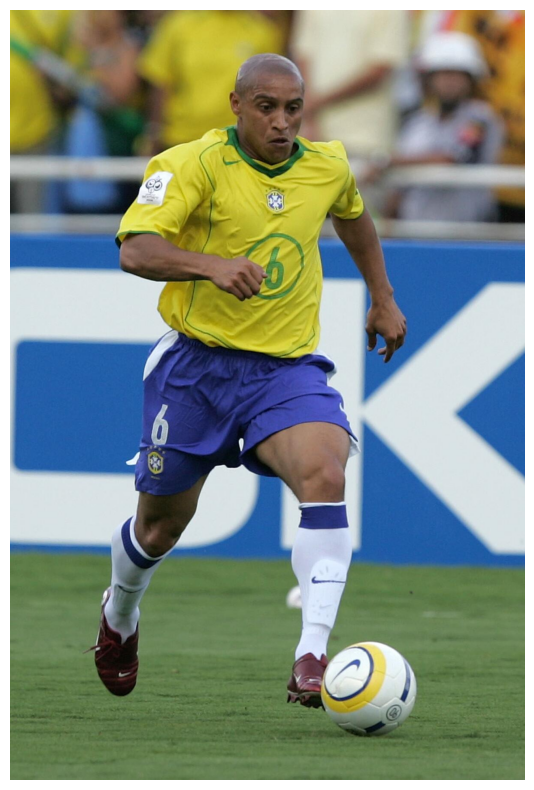

In [ ]:
# Loading the image using OpenCV.
img = cv2.imread("roberto-carlos-the-best-in-the-world.jpg")
# Getting the image's width and height.
img_width = img.shape[1]
img_height = img.shape[0]
# Creating a figure and a set of axes.
fig, ax = plt.subplots(figsize=(10, 10))
ax.axis('off')
ax.imshow(img[...,::-1])
plt.show()

In [ ]:
with mp_pose.Pose(static_image_mode=True) as pose:
    """
    This function utilizes the MediaPipe library to detect and draw 'landmarks'
    (reference points) on an image. 'Landmarks' are points of interest
    that represent various body parts detected in the image.

    Args:
        static_image_mode: a boolean to inform if the image is static (True) or sequential (False).
    """

    # Make a copy of the original image.
    annotated_img = img.copy()

    # Processes the image.
    results = pose.process(img)

    # Set the circle radius for drawing the 'landmarks'.
    # The radius is scaled as a percentage of the image's height.
    circle_radius = int(.007 * img_height)

    # Specifies the drawing style for the 'landmarks'.
    point_spec = mp_drawing.DrawingSpec(color=(220, 100, 0), thickness=-1, circle_radius=circle_radius)

    # Draws the 'landmarks' on the image.
    mp_drawing.draw_landmarks(annotated_img,
                              landmark_list=results.pose_landmarks,
                              landmark_drawing_spec=point_spec)

/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


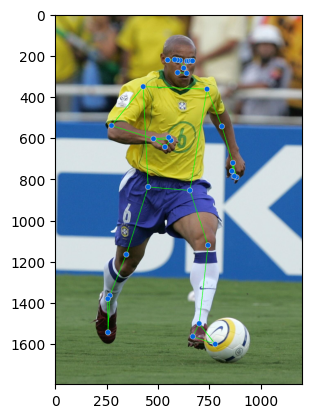

In [ ]:
# Make a copy of the original image.
annotated_img = img.copy()

# Specifies the drawing style for landmark connections.
line_spec = mp_drawing.DrawingSpec(color=(0, 255, 0), thickness=2)

# Draws both the landmark points and connections.
mp_drawing.draw_landmarks(
annotated_img,
landmark_list=results.pose_landmarks,
connections=mp_pose.POSE_CONNECTIONS,
landmark_drawing_spec=point_spec,
connection_drawing_spec=line_spec
)

plt.imshow(annotated_img[...,::-1])
plt.show()

In [ ]:
print(results.pose_landmarks)

landmark {
  x: 0.521608293
  y: 0.145984054
  z: -0.55975312
  visibility: 0.999934196
}
landmark {
  x: 0.534500837
  y: 0.127415806
  z: -0.534659803
  visibility: 0.999859691
}
landmark {
  x: 0.54231143
  y: 0.12699917
  z: -0.534602106
  visibility: 0.999805629
}
landmark {
  x: 0.550641954
  y: 0.126382917
  z: -0.534684658
  visibility: 0.999772847
}
landmark {
  x: 0.506992519
  y: 0.125607193
  z: -0.551868916
  visibility: 0.999903917
}
landmark {
  x: 0.495532036
  y: 0.12447843
  z: -0.551945508
  visibility: 0.999898434
}
landmark {
  x: 0.484692544
  y: 0.123600513
  z: -0.552005112
  visibility: 0.999913692
}
landmark {
  x: 0.557135701
  y: 0.126471788
  z: -0.27416113
  visibility: 0.999650717
}
landmark {
  x: 0.456551015
  y: 0.124368042
  z: -0.356806487
  visibility: 0.999949574
}
landmark {
  x: 0.532993853
  y: 0.160161048
  z: -0.448645324
  visibility: 0.999931335
}
landmark {
  x: 0.496061563
  y: 0.158373386
  z: -0.472223043
  visibility: 0.999978185
}
land

In [ ]:
# Select the coordinates of the points of interest.
l_knee_x = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_KNEE].x * img_width)
l_knee_y = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_KNEE].y * img_height)

l_ankle_x = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_ANKLE].x * img_width)
l_ankle_y = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_ANKLE].y * img_height)

l_heel_x = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_HEEL].x * img_width)
l_heel_y = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_HEEL].y * img_height)

l_foot_index_x = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_FOOT_INDEX].x * img_width)
l_foot_index_y = int(results.pose_landmarks.landmark[mp_pose.PoseLandmark.LEFT_FOOT_INDEX].y * img_height)

# Print the coordinates on the screen.
print('Left knee coordinates: (', l_knee_x,',',l_knee_y,')' )
print('Left ankle coordinates: (', l_ankle_x,',',l_ankle_y,')' )
print('Left heel coordinates: (', l_heel_x,',',l_heel_y,')' )
print('Left foot index coordinates: (', l_foot_index_x,',',l_foot_index_y,')' )

Left knee coordinates: ( 743 , 1122 )
Left ankle coordinates: ( 700 , 1502 )
Left heel coordinates: ( 669 , 1565 )
Left foot index coordinates: ( 778 , 1602 )


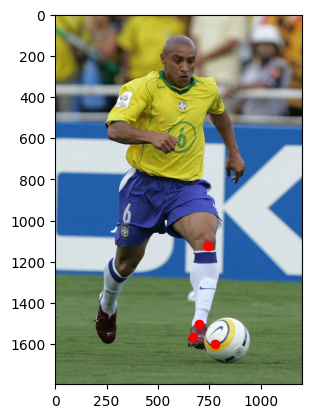

In [ ]:
# Displaying a graph with the selected points.
fig, ax = plt.subplots()
ax.imshow(img[:, :, ::-1])
ax.plot([l_knee_x, l_ankle_x, l_heel_x, l_foot_index_x], [l_knee_y, l_ankle_y, l_heel_y, l_foot_index_y], 'ro')
plt.show()

Convert to ONNX

Connection with SAM

In [ ]:
!pip install openvino==2024.6.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 MB 21.6 MB/s eta 0:00:00
  Attempting uninstall: openvino
    Found existing installation: openvino 2025.1.0
    Uninstalling openvino-2025.1.0:
      Successfully uninstalled openvino-2025.1.0


In [ ]:
#Import OpenVino libs
import openvino as ov
import openvino.properties as props
import openvino.properties.hint as hints

#Additional libs
import numpy as np
import cv2
import time

class ov_model():

  #Constructor
  def __init__(self, model_xml, mode = 0, layout = [2, 0, 1], threads = 1, info = False):

    #Init plugin
    self.plugin = ov.Core()

    #Configuration options
    configuration = {hints.performance_mode(): hints.PerformanceMode.LATENCY,
              hints.num_requests(): threads, props.inference_num_threads(): 1,   props.affinity(): props.Affinity.NUMA }
    if(mode == 0):
        self.plugin.set_property("CPU", configuration)

    #Load openvino model
    self.model = self.load_IR_to_IE(model_xml, model_xml[:-3] + "bin", mode)

    #Input layout
    self.layout = layout

    #Print model info
    if(info):

        #Save output names
        self.output_names = [input.get_any_name() for input in self.model.inputs]

        #Get input names
        self.input_names =[output.get_any_name() for output in self.model.outputs]

        print("Inputs: ")
        # Get the input names and shapes
        for input in self.model.inputs:
            input_name = input.get_any_name()
            input_shape = input.get_partial_shape()
            print(f"Input name: {input_name}, Shape: {input_shape}")

        print("Outputs: ")
        for output in self.model.outputs:
            output_name = output.get_any_name()
            output_shape = list(output.get_partial_shape().to_shape())
            print(f"Output name: {output_name}, Shape: {output_shape}")

  #Preprocessing conf
  def conf_prep(self, std, mean, width, height, normalize = True):

    #Save mean and std
    self.std = std
    self.mean = mean

    #Save input resolution
    self.width = width
    self.height = height

    #Normalize options
    self.normalize = normalize

  #Auxiliar functions: Loading model to inference engine
  def load_IR_to_IE(self, model_xml, model_bin, mode):

    #Load network
    net = self.plugin.read_model(model=model_xml)
    #net.batch_size = 10

    if(mode == 0):
      exec_net = self.plugin.compile_model(net, device_name="CPU", config={props.inference_num_threads(): 1})
      print("Model loaded: " + str(model_xml) + " (CPU)")
    elif(mode == 1):
      exec_net = self.plugin.compile_model(net, device_name="GPU", config={hints.inference_precision: 'f32'})#, config={props.inference_num_threads(): 1})
      print("Model loaded: " + str(model_xml) + " (GPU)")
    elif(mode == 2):
      exec_net = self.plugin.compile_model(net, device_name="MYRIAD", config={props.inference_num_threads(): 1})
      print("Model loaded: " + str(model_xml) + " (MYRIAD)")
    elif(mode == 3):
      exec_net = self.plugin.compile_model(net, device_name="VPU", config={props.inference_num_threads(): 1})
      print("Model loaded: " + str(model_xml) + " (VPU)")

    return exec_net

  #Syncrhonous inference
  def synchronous_inference(self, image):

    #Perform synchronous inference
    result = self.model(image)

    return result

  #Image preprocessing
  def prep_image(self, img_raw):

    #Resize image
    img_raw = cv2.resize(img_raw, (self.width, self.height))

    #Normalize pixels
    if(self.normalize):
      img = np.float32(img_raw)/255.0
    else:
      img = np.float32(img_raw)

    #Substract mean
    img -= (self.mean[0], self.mean[1], self.mean[2])

    #Adjust to std
    img[0, :, :] = img[0, :, :]/self.std[0]
    img[1, :, :] = img[1, :, :]/self.std[1]
    img[2, :, :] = img[2, :, :]/self.std[2]

    #Rearrange
    img = img.transpose(self.layout[0], self.layout[1], self.layout[2])
    img = img[np.newaxis, :, :, :]

    return img

  #Forward pass
  def forward(self, img, prep=True):

    #Preprocess img
    if(prep):
      img_prep = self.prep_image(img)
    else:
      img_prep = img.copy()

    #Run inference
    res = self.synchronous_inference(img_prep)
    inf_out_dict = {}
    # Iterate over the model outputs
    for output in self.model.outputs:
        output_name = output.get_any_name()  # Get the name of the output
        output_data = res[output_name]       # Get the corresponding data from res
        #print(f"Output name: {output_name}") # Print the output name
        inf_out_dict[output_name] = output_data  # Add to the dictionary
    return inf_out_dict

In [ ]:
class EffSAM():

    #Constructor
    def __init__(self, model_path):

        #Init model
        self.model = ov_model(model_path, mode = 0)

    #Get mask
    def process_frame(self, frame, pos_points, neg_points):

        print("==> Processing frame ..")

        #Merge points
        input_points = pos_points + neg_points
        input_labels = [1]*len(pos_points) + [0]*len(neg_points)

        #Prepare input
        img_tensor, pts_sampled, pts_labels = EffSAM.prepare_input(frame, input_points, input_labels)

        #Run inference
        print("==> Running SAM Inference ..")
        #start = timer()
        result = self.model.model([img_tensor, pts_sampled, pts_labels])
        #end = timer()
        #print(end - start) # Time in seconds, e.g. 5.38091952400282

        #Get mask
        print("==> Generating mask ..")
        predicted_logits, predicted_iou = result[0], result[1]
        predicted_mask = EffSAM.postprocess_results(predicted_iou, predicted_logits)

        #Normalize mask
        normalized_mask = np.repeat(predicted_mask[:, :, np.newaxis].astype("uint8"), 3, axis=2) * 255

        #cv2.imshow("mask", normalized_mask)
        #cv2.waitKey(-1)
        #plt.figure(figsize=(20, 20))
        #plt.axis("off")
        #plt.imshow(frame)
        #EffSAM.show_points(np.array(pos_points + neg_points), np.array(input_labels), plt.gca())
        #plt.figure(figsize=(20, 20))
        #plt.axis("off")
        #plt.imshow(frame)
        #EffSAM.show_anns(predicted_mask, plt.gca())
        #plt.show()

        return normalized_mask


    def prepare_input(input_image, points, labels):
        img_tensor = np.ascontiguousarray(input_image)[None, ...].astype(np.float32) / 255
        img_tensor = np.transpose(img_tensor, (0, 3, 1, 2))
        pts_sampled = np.reshape(np.ascontiguousarray(points), [1, 1, -1, 2])
        pts_labels = np.reshape(np.ascontiguousarray(labels), [1, 1, -1])

        return img_tensor, pts_sampled, pts_labels


    def postprocess_results(predicted_iou, predicted_logits):
        sorted_ids = np.argsort(-predicted_iou, axis=-1)
        predicted_iou = np.take_along_axis(predicted_iou, sorted_ids, axis=2)
        predicted_logits = np.take_along_axis(predicted_logits, sorted_ids[..., None, None], axis=2)

        return predicted_logits[0, 0, 0, :, :] >= 0

    def show_anns(mask, ax):
        ax.set_autoscale_on(False)
        img = np.ones((mask.shape[0], mask.shape[1], 4))
        img[:, :, 3] = 0
        # for ann in mask:
        #     m = ann
        color_mask = np.concatenate([np.random.random(3), [0.5]])
        img[mask] = color_mask
        ax.imshow(img)

    def show_points(coords, labels, ax, marker_size=375):
        pos_points = coords[labels == 1]
        neg_points = coords[labels == 0]
        ax.scatter(
            pos_points[:, 0],
            pos_points[:, 1],
            color="green",
            marker="*",
            s=marker_size,
            edgecolor="white",
            linewidth=1.25,
        )
        ax.scatter(
            neg_points[:, 0],
            neg_points[:, 1],
            color="red",
            marker="*",
            s=marker_size,
            edgecolor="white",
            linewidth=1.25,
        )

In [ ]:
import gdown

#Get models
!mkdir models
gdown.download("https://drive.google.com/file/d/1Pbp0_QWO4g8TNMJcUIX8oYQgphob1W_E/view?usp=drive_link", "models/efficient-sam_fp16.bin", quiet=False,fuzzy=True)
gdown.download("https://drive.google.com/file/d/1dva9oWAFXQ-qKJPvciyF9WCmaoqojduS/view?usp=drive_link", "models/efficient-sam_fp16.xml", quiet=False,fuzzy=True)

Downloading...
From: https://drive.google.com/uc?id=1Pbp0_QWO4g8TNMJcUIX8oYQgphob1W_E
To: /content/models/efficient-sam_fp16.bin
100%|██████████| 22.5M/22.5M [00:00<00:00, 104MB/s] 
Downloading...
From (original): https://drive.google.com/uc?id=1dva9oWAFXQ-qKJPvciyF9WCmaoqojduS
From (redirected): https://drive.google.com/uc?id=1dva9oWAFXQ-qKJPvciyF9WCmaoqojduS&confirm=t&uuid=fe4e28bd-d2d9-4ec1-874e-c0df96af47de
To: /content/models/efficient-sam_fp16.xml
100%|██████████| 861k/861k [00:00<00:00, 17.5MB/s]


'models/efficient-sam_fp16.xml'

In [ ]:
#Create model
sam = EffSAM("models/efficient-sam_fp16.xml")

Model loaded: models/efficient-sam_fp16.xml (CPU)


In [ ]:
def normalize_landmarks(frame, landmarks):

  #Init ouptut struct
  out = []

  #Extract landmarks
  for i in range(len(landmarks.landmark)):

    #Get data
    x = landmarks.landmark[i].x*frame.shape[1]
    y = landmarks.landmark[i].y*frame.shape[0]

    out.append([int(x), int(y)])

  return out

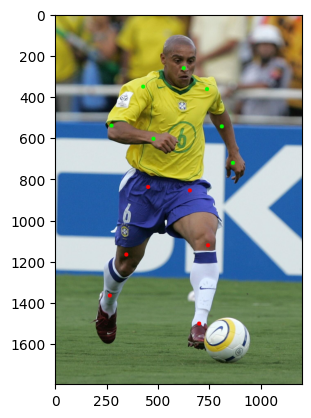

In [ ]:
#Get landmarks
landmarks = normalize_landmarks(img, results.pose_landmarks)

#Select a set of landmarks
lands_index_top = [0, 11, 12, 13, 14, 15, 16]
lands_index_bottom = [23, 24, 25, 26, 27, 28]
lands_top = []
for i in range(len(lands_index_top)):
  lands_top.append([landmarks[lands_index_top[i]][0], landmarks[lands_index_top[i]][1]])
lands_bot = []
for i in range(len(lands_index_bottom)):
  lands_bot.append([landmarks[lands_index_bottom[i]][0], landmarks[lands_index_bottom[i]][1]])

#Display landmarks
img_int = img.copy()
for i in range(len(lands_top)):
  cv2.circle(img_int, (lands_top[i][0], lands_top[i][1]), 10, (0, 255, 0), -1)
for i in range(len(lands_bot)):
  cv2.circle(img_int, (lands_bot[i][0], lands_bot[i][1]), 10, (0, 0, 255), -1)

plt.imshow(img_int[...,::-1])

==> Processing frame ..
==> Running SAM Inference ..
==> Generating mask ..
==> Processing frame ..
==> Running SAM Inference ..
==> Generating mask ..


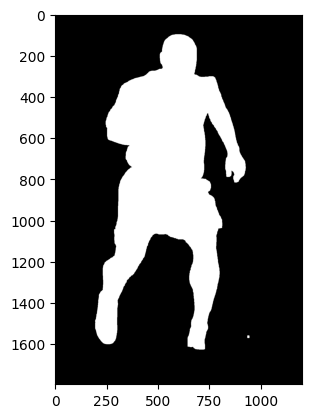

In [ ]:
#Run segmentation on image
mask_top = sam.process_frame(img, lands_top, [])
mask_bot = sam.process_frame(img, lands_bot, [])

#Merge masks
mask = mask_top + mask_bot

#Run Dilations to connect
kernel = np.ones((5, 5), np.uint8)
mask = cv2.dilate(mask, kernel, iterations=2)

plt.imshow(mask)

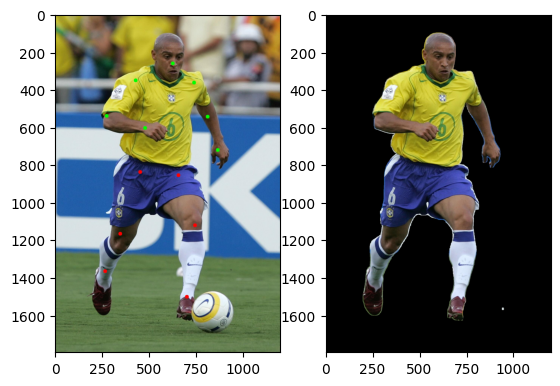

In [ ]:
#Apply mask
img_subs = img.copy()*mask.astype("bool")

#Display result
plt.figure(1)
plt.subplot(1,2,1)
plt.imshow(img_int[...,::-1])
plt.subplot(1,2,2)
plt.imshow(img_subs[...,::-1])